# Zenodo dataset checks

Purpose: find problems in the Zenodo caries dataset (`data/raw/zenodo_full`) before training YOLO.

Checks:
1. Every label file has an image
2. Every box lies inside its image
3. Class counts and empty label files
4. Exact duplicate images
5. Images per patient (for a leak-free split)
6. Visual check of a good and a bad label

YOLO label format: one box per line, `class x_centre y_centre width height`, with the last four as fractions (0-1) of the image size.

In [1]:
# Setup
from pathlib import Path
import hashlib
import re

import cv2
import matplotlib.pyplot as plt
import pandas as pd

REPO = Path.cwd().parents[2]                       # notebooks -> yolo_caries -> models -> repo root
RAW = REPO / "data/raw/zenodo_full"
IMAGES = RAW / "Images"
LABELS = RAW / "Annotations/Darknet_YOLO"
TOL = 0.01                                         # allow 1% rounding at image edges
assert LABELS.exists(), f"path not found: {LABELS}"

## 1. Checking if every image has a corresponding label in the dataset

Files are matched by their path without the extension, e.g. `no_retractors/Frontal/<name>`.

In [2]:
imgs = {p.relative_to(IMAGES).with_suffix("").as_posix() for p in IMAGES.rglob("*.jpg")} #gets all images in the directory
labs = {p.relative_to(LABELS).with_suffix("").as_posix() for p in LABELS.rglob("*.txt")} #gets all labels in the directory

orphans = sorted(labs - imgs)                      # label files with no image
print(len(imgs), "images,", len(labs), "label files")
print("labels without image:", len(orphans))
print("images without label (unannotated):", len(imgs - labs))
orphans

6265 images, 2245 label files
labels without image: 18
images without label (unannotated): 4038


['pilot/Mandibular/anonymous-1727845380707_Mandibular_View',
 'pilot/Mandibular/anonymous-1727846130649_Mandibular_View',
 'pilot/Mandibular/anonymous-1727849249910_Mandibular_View',
 'pilot/Mandibular/anonymous-1727849691134_Mandibular_View',
 'pilot/Mandibular/anonymous-1727850241443_Mandibular_View',
 'pilot/Mandibular/anonymous-1727852113159_Mandibular_View',
 'pilot/Mandibular/anonymous-1727852867244_Mandibular_View',
 'pilot/Mandibular/anonymous-1727856760983_Mandibular_View',
 'pilot/Mandibular/anonymous-1727857494246_Mandibular_View',
 'pilot/Maxillary_Occlusal/anonymous-1727845380707_Maxillary_Occlusal_View',
 'pilot/Maxillary_Occlusal/anonymous-1727849249910_Maxillary_Occlusal_View',
 'pilot/Maxillary_Occlusal/anonymous-1727849691134_Maxillary_Occlusal_View',
 'pilot/Maxillary_Occlusal/anonymous-1727850241443_Maxillary_Occlusal_View',
 'pilot/Maxillary_Occlusal/anonymous-1727852113159_Maxillary_Occlusal_View',
 'pilot/Maxillary_Occlusal/anonymous-1727852867244_Maxillary_Occlu

**Finding:** 18 label files have no image anywhere in the dataset, so they can't be used for training. About 64% of images have no label file. These are images with no annotation from the authors of the dataset.

**Decision:** ignore the orphan labels and drop the images without the label.

## 2. Every box lies inside its image

A box is bad if any edge falls outside 0-1 (with a 1% tolerance for rounding).

In [3]:
rows = []
for txt in LABELS.rglob("*.txt"):
    rel = txt.relative_to(LABELS).with_suffix("").as_posix()
    if rel not in imgs:                            # skip orphan labels (section 1)
        continue
    for line in txt.read_text().splitlines():
        if line.strip():
            c, x, y, w, h = map(float, line.split())
            rows.append({"file": rel, "cls": int(c), "x": x, "y": y, "w": w, "h": h})
boxes = pd.DataFrame(rows)

bad = (boxes.x - boxes.w / 2 < -TOL) | (boxes.x + boxes.w / 2 > 1 + TOL) | \
      (boxes.y - boxes.h / 2 < -TOL) | (boxes.y + boxes.h / 2 > 1 + TOL)
boxes["bad"] = bad
print(len(boxes), "boxes in", boxes.file.nunique(), "label files")
print(bad.sum(), "bad boxes in", boxes[bad].file.nunique(), "files")

6728 boxes in 2164 label files
42 bad boxes in 16 files


In [4]:
# Per file: are all boxes in a bad file wrong, or only some?
per_file = boxes.groupby("file").agg(n_boxes=("bad", "size"), n_bad=("bad", "sum"))
per_file[per_file.n_bad > 0]

,n_boxes,n_bad
file,,
no_retractors/Frontal/anonymous_003-007-1214-00_1732862917124_Frontal_View,1,1
no_retractors/Frontal/anonymous_003-008-1188-00_1732714947165_Frontal_View,5,5
no_retractors/Left_Lateral/anonymous_003-007-1214-00_1732862917124_Left_Lateral_View,1,1
no_retractors/Left_Lateral/anonymous_003-008-1116-00_1732364867658_Left_Lateral_View,3,3
no_retractors/Left_Lateral/anonymous_003-008-1140-00_1732538036389_Left_Lateral_View,2,2
no_retractors/Left_Lateral/anonymous_003-008-1188-00_1732714947165_Left_Lateral_View,5,5
no_retractors/Right_Lateral/anonymous_003-008-1140-00_1732538036389_Right_Lateral_View,1,1
no_retractors/Right_Lateral/anonymous_003-008-1188-00_1732714947165_Right_Lateral_View,5,5
retractors/Frontal/anonymous_003-007-1141-01_1732595713489_Frontal_View,1,1


42 boxes in 16 files lie outside the image, and in every one of those files all boxes are wrong. 

**Decision:** exclude these 16 images. 

## 3. Class counts and empty label files

Counts the boxes per class and label files with no boxes.
0 = 'D' = decay on adult teeth
1 = 'd' = decay on baby teeth


In [5]:
print(boxes.cls.value_counts())
empty = [t for t in LABELS.rglob("*.txt")
         if t.relative_to(LABELS).with_suffix("").as_posix() in imgs and not t.read_text().strip()]
print("empty label files:", len(empty))

cls
0    6174
1     554
Name: count, dtype: int64
empty label files: 63


**Finding:** `d` is about 8% of boxes. Empty label files are images that were annotated but have no caries boxes (some have only an `M` missing-tooth box).

**Decision:** merge `D` and `d` into one `caries` class and treat empty label files as no-caries images.

## 4. Exact duplicate images

Two files with the same MD5 hash have identical bytes. 

In [6]:
hashes = pd.Series({p: hashlib.md5(p.read_bytes()).hexdigest() for p in IMAGES.rglob("*.jpg")})
print("exact duplicate images:", hashes.duplicated().sum())

exact duplicate images: 0


**Finding:** no exact duplicates inside `zenodo_full`. 

## 5. Images per patient

The patient ID is in the filename, e.g. `anonymous_003-007-1214-00_...`. Some files use `_` instead of `-`.

In [7]:
def patient_id(name):
    m = re.search(r"anonymous_(\d+[-_]\d+[-_]\d+)", name)
    return m.group(1).replace("_", "-") if m else None

pid = pd.Series({p: patient_id(p) for p in imgs & labs})
print("images with no patient ID:", pid.isna().sum())
print("patients:", pid.nunique())
print("patients by number of photos:")
print(pid.value_counts().value_counts().sort_index())

images with no patient ID: 270
patients: 1020
patients by number of photos:
count
1    274
2    619
3     76
4     38
5     13
Name: count, dtype: int64


In [8]:
# Does the authors' benchmark split keep each patient in one split?
BENCH = REPO / "data/raw/zenodo_benchmark"
split_of = pd.Series({t.stem: s for s in ["train", "valid", "test"]
                      for t in (BENCH / s / "yolo").glob("*.txt")})
splits_per_patient = split_of.groupby(split_of.index.map(patient_id)).nunique()   # images without an ID are dropped
print("patients:", len(splits_per_patient))
print("patients in more than one split:", (splits_per_patient > 1).sum())

patients: 1020
patients in more than one split: 280


**Finding:** the labelled images come from 1,020 patients. Most have 2 photos, and 746 have 2 or more, so the same mouth can appear more than once. The 270 labelled `pilot` images have no patient ID. The authors' benchmark split puts 280 of 1,020 patients in more than one split.

**Decision:** split train/val/test by patient, not by image, so one patient's photos never end up in both train and test. Put all `pilot` images in train as well.

## 6. Visual check

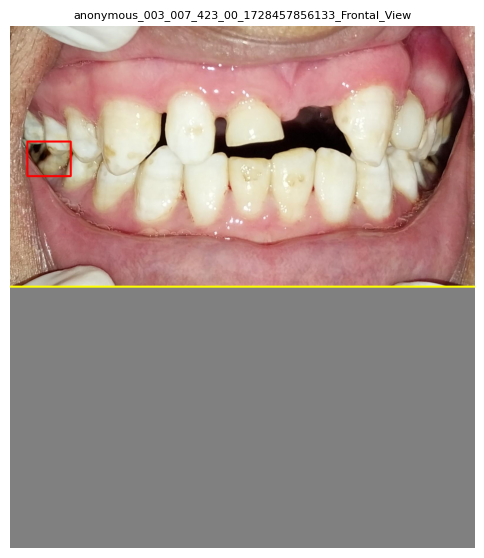

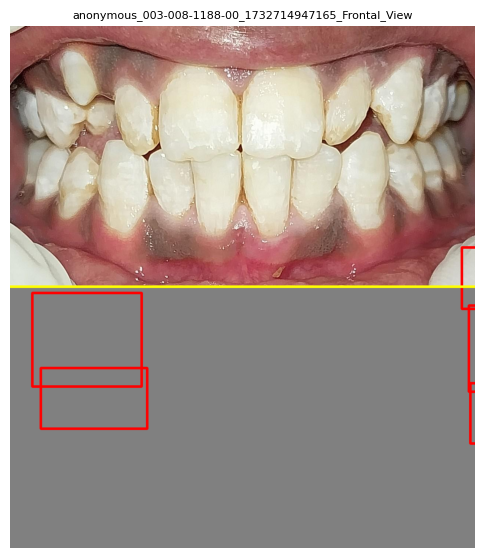

In [9]:
def show_label(rel):
    img = cv2.imread(str(IMAGES / f"{rel}.jpg"))
    assert img is not None, f"image not found: {rel}"
    H, W = img.shape[:2]
    canvas = cv2.copyMakeBorder(img, 0, H, 0, 0, cv2.BORDER_CONSTANT, value=(128, 128, 128))
    for line in (LABELS / f"{rel}.txt").read_text().splitlines():
        if not line.strip():
            continue
        c, x, y, w, h = map(float, line.split())
        x0, y0 = int((x - w / 2) * W), int((y - h / 2) * H)   # fractions -> pixels
        x1, y1 = int((x + w / 2) * W), int((y + h / 2) * H)
        cv2.rectangle(canvas, (x0, y0), (x1, y1), (0, 0, 255), max(2, W // 250))
    cv2.line(canvas, (0, H), (W, H), (0, 255, 255), max(2, W // 250))
    plt.figure(figsize=(6, 7))
    plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    plt.title(rel.split("/")[-1], fontsize=8)
    plt.axis("off")
    plt.show()

show_label("no_retractors/Frontal/anonymous_003_007_423_00_1728457856133_Frontal_View")    # good
show_label("no_retractors/Frontal/anonymous_003-008-1188-00_1732714947165_Frontal_View")   # bad: 5 boxes off-image

## Summary

| Check | Result | Decision |
|---|---|---|
| Images without label | 4,038 (unannotated) | Exclude |
| Labels without image | 18 (all `pilot`) | Ignore |
| Boxes outside image | 42 boxes in 16 files | Exclude those 16 images |
| Classes | D 6,174 · d 554 | Merge into one `caries` class |
| Empty label files | 63 | Keep as no-caries images |
| Exact duplicates | 0 | — |
| Patients | 1,020, most with 2 labelled photos; 270 pilot images without ID; benchmark split leaks 280 patients | Split by patient; pilot to train |

**Not covered by these checks:** boxes inside the image but on the wrong tooth (only visual review catches these), and caries the annotators never boxed.